In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

## Step 2: Define image settings and dataset paths
We'll use:
- Image size: 224 × 224 pixels.
- Batch size: 16, to keep memory usage manageable.
- Image format: RGB.
- Random seed: 42, for reproducibility.

In [2]:
PROJECT_DIR = Path("..")
DATA_DIR = PROJECT_DIR / "dataset" / "processed"

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "validation"
TEST_DIR = DATA_DIR / "test"

print("Training folder exists:", TRAIN_DIR.exists())
print("Validation folder exists:", VAL_DIR.exists())
print("Testing folder exists:", TEST_DIR.exists())

Training folder exists: True
Validation folder exists: True
Testing folder exists: True


## Step 3: Load the training, validation and testing images
We'll use TensorFlow's image_dataset_from_directory().

This function:
- Reads images directly from their folders.
- Assigns labels based on folder names.
- Resizes images to 224 × 224.
- Loads images in batches of 16.
- Shuffles the training data only.

In [3]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

Found 1506 files belonging to 3 classes.
Found 323 files belonging to 3 classes.
Found 323 files belonging to 3 classes.


## Step 4: Check the class names and labels
We need to know which numerical label corresponds to each disease.

In [4]:
class_names = train_ds.class_names

print("Class names and their numerical labels:")

for index, class_name in enumerate(class_names):
    print(f"{index}: {class_name}")

Class names and their numerical labels:
0: Potato___Early_blight
1: Potato___Late_blight
2: Potato___healthy


## Step 5: Normalize pixel values
Images contain pixel values ranging from 0 to 255. Neural networks generally train more effectively when inputs are scaled to a smaller range.

In [5]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)

val_ds = val_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)

test_ds = test_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)

print("Image normalization completed.")

Image normalization completed.


## Step 6: Apply data augmentation
Data augmentation creates slightly modified versions of training images to help the model generalize to new images.

We'll use:
- Random horizontal flipping.
- Small random rotations.
- Random zooming.
We will apply augmentation only during training, not validation or testing.

In [6]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

print("Data augmentation pipeline created.")

Data augmentation pipeline created.


## Step 7: Optimize the dataset pipeline
We'll use TensorFlow's prefetch() to prepare batches while the model processes the previous batch.

In [7]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("Dataset pipelines optimized.")

Dataset pipelines optimized.


## Step 8: Visualize augmented images
Let's see how the augmentation transformations affect the training images.

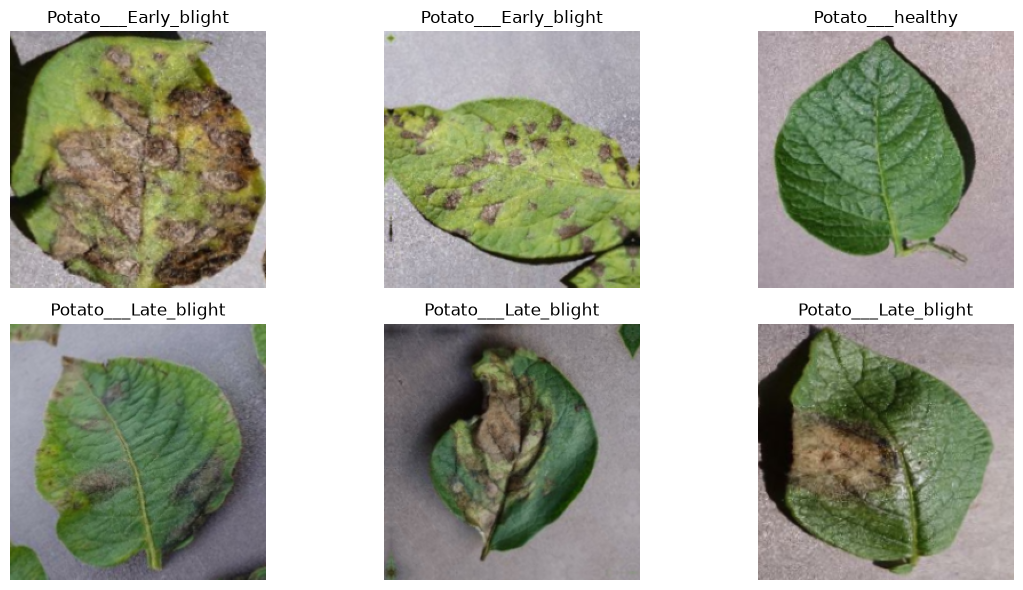

In [8]:
images, labels = next(iter(train_ds))

augmented_images = data_augmentation(images, training=True)

plt.figure(figsize=(12, 6))

for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(augmented_images[i].numpy())
    plt.title(class_names[int(labels[i])])
    plt.axis("off")

plt.tight_layout()
plt.show()

## Step 9: Verify normalized pixel values and batch shape
Let's confirm that the images have the expected dimensions and pixel range.

In [9]:
images, labels = next(iter(train_ds))

print("Batch shape:", images.shape)
print("Label shape:", labels.shape)
print("Minimum pixel value:", tf.reduce_min(images).numpy())
print("Maximum pixel value:", tf.reduce_max(images).numpy())

Batch shape: (16, 224, 224, 3)
Label shape: (16,)
Minimum pixel value: 0.0
Maximum pixel value: 0.9935966
